In [3]:
import zipfile, glob, os
import pandas as pd
from google.colab import files

if not os.path.exists("archive.zip"):
    files.upload()          # pick archive.zip from your Downloads

with zipfile.ZipFile("archive.zip") as z:
    print(z.namelist())
    z.extractall("data")

csv_path = glob.glob("data/**/*.csv", recursive=True)[0]
print("Using:", csv_path)
df = pd.read_csv(csv_path)
print(df.shape)
df.isna().sum()

['StudentPerformanceFactors.csv']
Using: data/StudentPerformanceFactors.csv
(6607, 20)


,0
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0


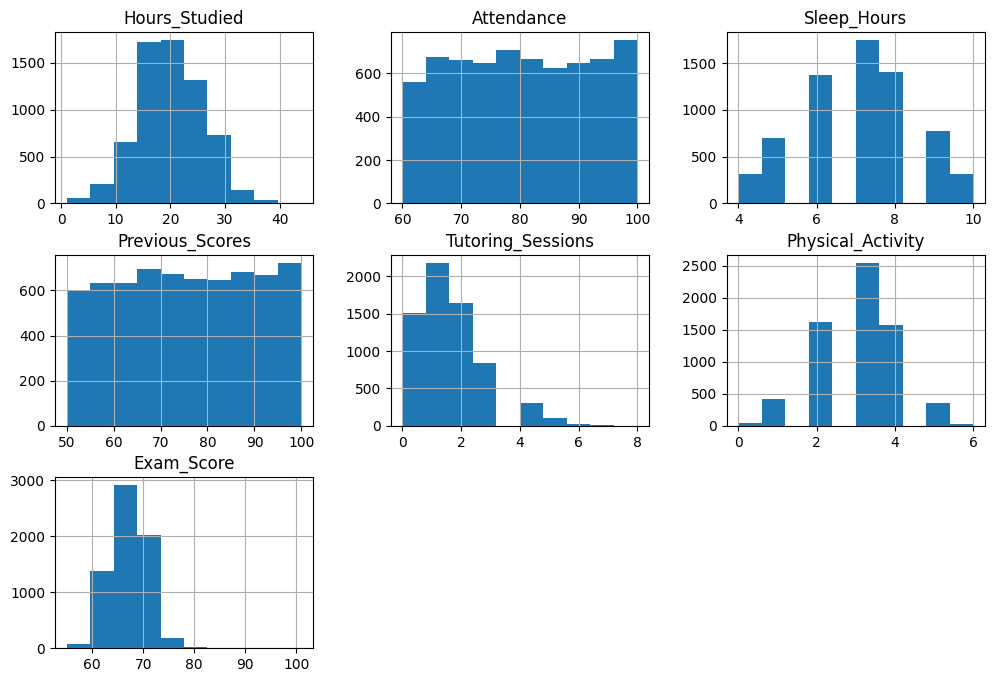

,Exam_Score
Sleep_Hours,-0.017022
Physical_Activity,0.027824
Tutoring_Sessions,0.156525
Previous_Scores,0.175079
Hours_Studied,0.445455
Attendance,0.581072
Exam_Score,1.000000


In [4]:
import matplotlib.pyplot as plt
df.hist(figsize=(12,8)); plt.show()
df.corr(numeric_only=True)["Exam_Score"].sort_values()

In [5]:
import pickle, sklearn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

NUM = ["Hours_Studied","Attendance","Sleep_Hours","Previous_Scores","Tutoring_Sessions"]
CAT = ["Motivation_Level","Parental_Involvement","Access_to_Resources"]
TARGET = "Exam_Score"

data = df[NUM+CAT+[TARGET]].dropna()
data[TARGET] = data[TARGET].clip(upper=100)   # the dataset has a stray 101

X_tr, X_te, y_tr, y_te = train_test_split(data[NUM+CAT], data[TARGET], test_size=0.2, random_state=42)

def make(reg):
    pre = ColumnTransformer(
        [("cat", OrdinalEncoder(categories=[["Low","Medium","High"]]*3), CAT)],
        remainder="passthrough")
    return Pipeline([("pre", pre), ("reg", reg)])

best, best_r2 = None, -9
for name, reg in {"Linear": LinearRegression(),
                  "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42)}.items():
    m = make(reg).fit(X_tr, y_tr)
    p = m.predict(X_te)
    r2 = r2_score(y_te, p)
    print(name, "MAE:", round(mean_absolute_error(y_te, p), 2), "R2:", round(r2, 3))
    if r2 > best_r2:
        best, best_r2 = m, r2

print("sklearn version:", sklearn.__version__)   # NOTE THIS DOWN

Linear MAE: 0.9 R2: 0.717
RandomForest MAE: 1.19 R2: 0.633
sklearn version: 1.6.1


In [6]:
pickle.dump(best, open("academic_advisor.pkl", "wb"))
files.download("academic_advisor.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
   pip install groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 4.3 MB/s eta 0:00:00


In [9]:
models = client.models.list()
for m in sorted(models.data, key=lambda m: m.id):
    print(m.id)

allam-2-7b
canopylabs/orpheus-arabic-saudi
canopylabs/orpheus-v1-english
meta-llama/llama-prompt-guard-2-22m
meta-llama/llama-prompt-guard-2-86m
openai/gpt-oss-120b
openai/gpt-oss-20b
openai/gpt-oss-safeguard-20b
qwen/qwen3.8-27b
whisper-large-v3
whisper-large-v3-turbo


In [10]:
MODEL = "openai/gpt-oss-20b"

r = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": "Say hello in one short sentence."}],
    max_completion_tokens=800,
    reasoning_effort="low",
)
print(repr(r.choices[0].message.content))

'Hi there!'


In [11]:
!ls -la academic_advisor.pkl

-rw-r--r-- 1 root root 2399 Oct 13 10:08 academic_advisor.pkl


In [12]:
%%writefile main.py
import os
import pickle
from pathlib import Path
from typing import Literal

import pandas as pd
from fastapi import FastAPI
from fastapi.responses import HTMLResponse
from pydantic import BaseModel, Field

BASE = Path(__file__).parent
with open(BASE / "academic_advisor.pkl", "rb") as f:
    model = pickle.load(f)

app = FastAPI(title="Academic Advisor")
Level = Literal["Low", "Medium", "High"]


class Student(BaseModel):
    Hours_Studied: float = Field(ge=0, le=80)
    Attendance: float = Field(ge=0, le=100)
    Sleep_Hours: float = Field(ge=0, le=16)
    Previous_Scores: float = Field(ge=0, le=100)
    Tutoring_Sessions: int = Field(ge=0, le=10)
    Motivation_Level: Level
    Parental_Involvement: Level
    Access_to_Resources: Level


def to_grade(score: float) -> str:
    for cutoff, g in [(70, "A"), (60, "B"), (50, "C"), (45, "D"), (40, "E")]:
        if score >= cutoff:
            return g
    return "F"


def advise(s: Student, score: float) -> list[str]:
    tips = []
    if s.Attendance < 75:
        tips.append("Attendance is below 75%. You may be barred from the exam, so fix this first.")
    if s.Hours_Studied < 10:
        tips.append("Raise self-study to at least 10-15 hours a week.")
    if s.Sleep_Hours < 6:
        tips.append("Sleep under 6 hours hurts recall. Aim for 7-8.")
    if s.Previous_Scores < 55:
        tips.append("Weak previous results: revisit the foundations and see your level adviser.")
    if s.Tutoring_Sessions == 0 and score < 70:
        tips.append("Try peer tutoring or a study group.")
    if s.Motivation_Level == "Low":
        tips.append("Set small weekly goals and track them to rebuild momentum.")
    if score < 50:
        tips.append("Predicted score is below a C. Prioritise this course in your revision timetable.")
    if not tips:
        tips.append("You're on track. Keep your current routine.")
    return tips


def ai_plan(s: Student, score: float, grade: str, tips: list[str]) -> str | None:
    key = os.getenv("GROQ_API_KEY")
    if not key:
        return None  # app still works without the LLM
    try:
        from groq import Groq

        client = Groq(api_key=key)
        prompt = (
            f"A student's profile: {s.model_dump()}.\n"
            f"A trained model predicts an exam score of {score:.1f} (grade {grade}).\n"
            f"Flagged issues: {tips}.\n"
            "Write a short, encouraging 5-line weekly study plan. "
            "Use only the numbers given. Do not invent facts."
        )
        r = client.chat.completions.create(
            model="openai/gpt-oss-20b",
            messages=[{"role": "user", "content": prompt}],
            max_completion_tokens=1000,
            reasoning_effort="low",
        )
        return r.choices[0].message.content or None
    except Exception:
        return None  # fall back to rule-based advice


@app.post("/predict")
def predict(s: Student):
    row = pd.DataFrame([s.model_dump()])
    score = min(float(model.predict(row)[0]), 100.0)
    grade = to_grade(score)
    tips = advise(s, score)
    return {"predicted_score": round(score, 1), "grade": grade, "advice": tips,
            "ai_plan": ai_plan(s, score, grade, tips)}


PAGE = """<!doctype html><html><head><meta charset=utf-8><title>Academic Advisor</title>
<style>body{font-family:sans-serif;max-width:480px;margin:2rem auto;padding:0 1rem}
label{display:block;margin-top:.7rem}input,select{width:100%;padding:.4rem}button{margin-top:1rem;padding:.6rem 1rem}
#out{margin-top:1.5rem;padding:1rem;background:#eef;border-radius:8px;display:none}</style></head><body>
<h2>AI Academic Advisor</h2><form id=f></form><button onclick=go()>Get advice</button><div id=out></div>
<script>
const N={Hours_Studied:"Study hours / week",Attendance:"Attendance %",Sleep_Hours:"Sleep hours / night",
Previous_Scores:"Previous score %",Tutoring_Sessions:"Tutoring sessions / month"};
const S={Motivation_Level:"Motivation",Parental_Involvement:"Parental involvement",Access_to_Resources:"Access to resources"};
f.innerHTML=Object.entries(N).map(([k,v])=>`<label>${v}<input id=${k} type=number step=any></label>`).join("")+
Object.entries(S).map(([k,v])=>`<label>${v}<select id=${k}><option>Low<option selected>Medium<option>High</select></label>`).join("");
async function go(){const b={};for(const k in N)b[k]=parseFloat(document.getElementById(k).value);
for(const k in S)b[k]=document.getElementById(k).value;
const r=await fetch("/predict",{method:"POST",headers:{"Content-Type":"application/json"},body:JSON.stringify(b)});
const d=await r.json();out.style.display="block";
out.innerHTML=r.ok?`<b>Predicted score: ${d.predicted_score} (Grade ${d.grade})</b><ul>${d.advice.map(a=>`<li>${a}</li>`).join("")}</ul>${d.ai_plan?"<p><b>AI study plan:</b><br>"+d.ai_plan.replace(/\\n/g,"<br>")+"</p>":""}`:"Check your inputs.";}
</script></body></html>"""


@app.get("/", response_class=HTMLResponse)
def home():
    return PAGE

Writing main.py


In [13]:
!head -5 main.py

import os
import pickle
from pathlib import Path
from typing import Literal



In [14]:
import os
os.makedirs("tests", exist_ok=True)
open("tests/__init__.py", "w").close()

# Makes sure tests never call the real Groq API
open("conftest.py", "w").write('''import pytest

@pytest.fixture(autouse=True)
def no_real_llm_calls(monkeypatch):
    monkeypatch.delenv("GROQ_API_KEY", raising=False)
''')

open("tests/test_api.py", "w").write('''from fastapi.testclient import TestClient
from main import app

client = TestClient(app)
GOOD = dict(Hours_Studied=20, Attendance=92, Sleep_Hours=7, Previous_Scores=80,
            Tutoring_Sessions=2, Motivation_Level="High",
            Parental_Involvement="Medium", Access_to_Resources="High")


def test_predict_ok():
    r = client.post("/predict", json=GOOD)
    assert r.status_code == 200
    assert 0 <= r.json()["predicted_score"] <= 100


def test_weak_student_gets_warning():
    bad = dict(GOOD, Attendance=50, Hours_Studied=2)
    advice = client.post("/predict", json=bad).json()["advice"]
    assert any("Attendance" in a for a in advice)


def test_invalid_input_rejected():
    assert client.post("/predict", json=dict(GOOD, Motivation_Level="Huge")).status_code == 422


def test_ai_plan_is_none_without_key():
    assert client.post("/predict", json=GOOD).json()["ai_plan"] is None


def test_ai_plan_used_when_llm_available(monkeypatch):
    import main
    monkeypatch.setattr(main, "ai_plan", lambda *a, **k: "Study plan here")
    assert client.post("/predict", json=GOOD).json()["ai_plan"] == "Study plan here"
''')

!python -m pytest -q

.....                                                                    [100%]
5 passed in 1.87s


In [15]:
import sys, threading, time, requests, nest_asyncio, uvicorn
nest_asyncio.apply()
sys.path.insert(0, "/content")
import main

# start the web server in the background
threading.Thread(
    target=lambda: uvicorn.run(main.app, host="0.0.0.0", port=8000, log_level="warning"),
    daemon=True,
).start()
time.sleep(3)

# send two test students to the running app
strong = dict(Hours_Studied=25, Attendance=95, Sleep_Hours=7, Previous_Scores=85, Tutoring_Sessions=2,
              Motivation_Level="High", Parental_Involvement="High", Access_to_Resources="High")
weak = dict(Hours_Studied=4, Attendance=55, Sleep_Hours=5, Previous_Scores=50, Tutoring_Sessions=0,
            Motivation_Level="Low", Parental_Involvement="Low", Access_to_Resources="Low")

for name, s in [("STRONG", strong), ("WEAK", weak)]:
    print(name, requests.post("http://127.0.0.1:8000/predict", json=s).json(), "\n")

STRONG {'predicted_score': 74.9, 'grade': 'A', 'advice': ["You're on track. Keep your current routine."], 'ai_plan': '1. Keep up the 25 hours of focused study this week—steady progress leads to steady gains.  \n2. Maintain your 95% attendance; every class counts toward mastering the material.  \n3. Aim for 7 hours of sleep each night so your brain stays sharp during review sessions.  \n4. Build on your 85 previous score by reviewing key concepts in the 2 tutoring sessions.  \n5. Leverage the high motivation, parental involvement, and resources available—stay confident and on track!'} 

WEAK {'predicted_score': 52.9, 'grade': 'C', 'advice': ['Attendance is below 75%. You may be barred from the exam, so fix this first.', 'Raise self-study to at least 10-15 hours a week.', 'Sleep under 6 hours hurts recall. Aim for 7-8.', 'Weak previous results: revisit the foundations and see your level adviser.', 'Try peer tutoring or a study group.', 'Set small weekly goals and track them to rebuild mo

In [16]:
from google.colab import files
for f in ["main.py", "conftest.py", "tests/test_api.py"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>